# Stock Market Prediction (Financial Forecasting)
## Comparative Study: Classical Econometric ARIMA vs. Deep Learning LSTM

### Project Overview
Financial market forecasting is a central challenge in quantitative finance and machine learning. Stock price series exhibit high volatility, non-stationarity, and non-linear patterns. This notebook investigates and contrasts two distinct modeling paradigms:
1. **Classical Statistical Modeling (ARIMA)**: Rooted in the Box-Jenkins methodology, utilizing autoregression, differencing, and moving averages on stationary representations of time series.
2. **Deep Learning Sequence Modeling (LSTM)**: Long Short-Term Memory recurrent neural networks, capable of capturing long-range temporal dependencies and non-linear patterns without strict distributional assumptions.

Both models are trained on the chronological 80% partition of historical data and evaluated on the final 20% holdout test partition on the exact same test dates.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure src/ package is in path
sys.path.append(os.path.abspath(".."))

from src.utils import set_random_seeds, calculate_metrics
from src.data_loader import download_stock_data
from src.stationarity import perform_adf_test, plot_rolling_statistics, make_stationary
from src.arima_model import plot_acf_pacf_diagnostics, train_and_forecast_arima
from src.lstm_model import train_and_forecast_lstm
from src.visualize import plot_model_comparison, save_and_display_metrics

# Set random seeds for deterministic reproducibility
set_random_seeds(42)
%matplotlib inline

mkdir -p failed for path /home/monodip/.config/matplotlib: [Errno 30] Read-only file system: '/home/monodip/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-62mzljd_ because there was an issue with the default path (/home/monodip/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


I0000 00:00:1795466477.951536      21 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795466479.805712      21 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### 1. Historical Stock Data Ingestion
We fetch daily OHLCV historical prices using `yfinance` for ticker symbol **AAPL** (Apple Inc.) from 2015-01-01 to present.
Our pipeline:
- Explicitly sets `auto_adjust=False` to handle adjusted prices consistently.
- Cleans and flattens yfinance MultiIndex headers into a 1D numeric 'Close' series.
- Seamlessly falls back to cached local CSV data in `data/` if offline.

In [2]:
ticker = "AAPL"
start_date = "2015-01-01"

df = download_stock_data(ticker=ticker, start=start_date, data_dir="../data")
print(f"Dataset shape: {df.shape}")
df[['Open', 'High', 'Low', 'Close', 'Volume']].tail()

Cookie/crumb fetch failed (DNSError), continuing without crumb


$AAPL: possibly delisted; no price data found  (1d 2015-01-01 -> 2026-11-24)



1 Failed download:


['AAPL']: possibly delisted; no price data found  (1d 2015-01-01 -> 2026-11-24)


[INFO] Fetching historical data for AAPL from 2015-01-01 to 2026-11-24...
[WARNING] Online download failed (yfinance returned empty dataset for ticker AAPL.). Attempting local CSV fallback...
[INFO] Fallback activated: Loading cached data from ../data/AAPL_raw.csv
[INFO] Loaded 2991 records from offline cache.
Dataset shape: (2991, 6)


,Open,High,Low,Close,Volume
Date,,,,,
2026-11-17,352.829987,355.359985,349.670013,351.910004,37407500
2026-11-18,351.940002,356.420013,351.470001,352.450012,34209900
2026-11-19,352.910004,355.279999,346.470001,349.209991,40906900
2026-11-20,352.869995,354.339996,340.559998,342.559998,80464200
2026-11-23,347.779999,352.600006,345.442200,351.269989,32562496


### 2. Time Series Stationarity Analysis
A stationary time series has statistical properties (mean, variance, autocorrelation) that remain constant over time.
We analyze stationarity using:
1. **30-Day Rolling Mean and Standard Deviation**
2. **Augmented Dickey-Fuller (ADF) Hypothesis Test**:
   - $H_0$ (Null Hypothesis): The series contains a unit root (non-stationary).
   - $H_1$ (Alternative Hypothesis): The series does not contain a unit root (stationary).
   - If $p \le 0.05$, we reject $H_0$ in favor of stationarity.

In [3]:
closing_series = df["Close"]

# Plot rolling statistics
plot_rolling_statistics(
    closing_series,
    window=30,
    save_path="../outputs/stationarity_rolling.png",
    title=f"{ticker} Closing Price - 30-Day Rolling Statistics"
)

# Perform ADF test and apply differencing if non-stationary
stationary_series, transform_type, d_order, adf_results = make_stationary(
    closing_series,
    save_path="../outputs/stationarity_transformed.png"
)

[INFO] Rolling statistics plot saved to ../outputs/stationarity_rolling.png
 Augmented Dickey-Fuller Test: Raw Closing Price
 ADF Statistic        : 1.272531
 p-value              : 9.964506e-01
 Lags Used            : 9
 Number of Observations: 2981
 Critical Values:
     1% : -3.4325
     5% : -2.8625
    10% : -2.5673
-----------------------------------------------------------------
 Result: Fail to reject H0 at 5% alpha. The series is NON-STATIONARY.
 Augmented Dickey-Fuller Test: First Differenced Series (d=1)
 ADF Statistic        : -18.868016
 p-value              : 0.000000e+00
 Lags Used            : 8
 Number of Observations: 2981
 Critical Values:
     1% : -3.4325
     5% : -2.8625
    10% : -2.5673
-----------------------------------------------------------------
 Result: Reject H0 at 5% alpha. The series is STATIONARY.


[INFO] Transformed stationary plot saved to ../outputs/stationarity_transformed.png


### 3. Chronological Train / Test Split
Time series data must **never be randomly shuffled**, as shuffling causes severe lookahead bias and data leakage.
We partition chronologically into:
- **80% Training Set**: Used for parameter estimation, differencing diagnostics, and hyperparameter tuning.
- **20% Holdout Test Set**: Strictly reserved for out-of-sample evaluation on identical calendar dates.

In [4]:
split_idx = int(len(closing_series) * 0.8)
train_series = closing_series.iloc[:split_idx]
test_series = closing_series.iloc[split_idx:]

print(f"Train period: {train_series.index[0].date()} to {train_series.index[-1].date()} ({len(train_series)} days)")
print(f"Test period : {test_series.index[0].date()} to {test_series.index[-1].date()} ({len(test_series)} days)")

Train period: 2015-01-02 to 2024-07-05 (2392 days)
Test period : 2024-07-08 to 2026-11-23 (599 days)


### 4. Statistical ARIMA Modeling
The Autoregressive Integrated Moving Average (ARIMA) model captures temporal autocorrelation:
$$ARIMA(p, d, q)$$
- **p**: Autoregressive order (lags of $y_t$)
- **d**: Integration degree (differencing order)
- **q**: Moving average order (lags of forecast errors $\epsilon_t$)

We inspect ACF/PACF diagnostic plots and conduct a grid search over $(p, d, q)$ minimizing the Akaike Information Criterion (AIC).

In [5]:
# Diagnostic Autocorrelation plots
plot_acf_pacf_diagnostics(
    stationary_series,
    lags=30,
    save_path="../outputs/acf_pacf.png",
    title_suffix=f"{ticker} Transformed ({transform_type})"
)

# Train optimal ARIMA and forecast test horizon
arima_forecast, arima_model, arima_metrics = train_and_forecast_arima(
    train_series=train_series,
    test_series=test_series,
    order=None,
    transform_type=transform_type
)

[INFO] ACF and PACF diagnostic plots saved to ../outputs/acf_pacf.png
[INFO] Starting ARIMA grid search over (p, d, q) configurations on training set...


[INFO] Optimal ARIMA order found: (0, 1, 0) with AIC = 9735.41
[INFO] Fitting ARIMA(0, 1, 0) on training data (2392 points)...
[INFO] ARIMA(0, 1, 0) Test Results -> MAE: 38.9678, RMSE: 53.1896


### 5. Deep Learning LSTM Modeling
Long Short-Term Memory (LSTM) networks address vanishing gradients in traditional RNNs using gating mechanisms (input, forget, and output gates).

Key engineering considerations:
- **MinMaxScaler Normalization**: Scaler is fit exclusively on the training partition ($0.0$ to $1.0$).
- **Sliding Window Sequencing**: 60 consecutive days of past prices are used as input to predict the next day's price.
- **Date Alignment**: The test sequence generator utilizes the final 60 days of the training set as history, guaranteeing that the first test prediction targets $t = \text{split\_idx}$ with zero missing test dates.

In [6]:
lstm_forecast, lstm_model, lstm_metrics, _, _ = train_and_forecast_lstm(
    series=closing_series,
    seq_length=60,
    train_ratio=0.8,
    epochs=25,
    batch_size=32,
    patience=5,
    seed=42
)

[INFO] Train sequences: (2332, 60, 1), Test sequences: (599, 60, 1)
[INFO] Test sequence count (599) perfectly matches test set size (599).


[INFO] Training LSTM model (epochs=25, batch_size=32)...
Epoch 1/25


E0000 00:00:1795466483.590234      21 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


 1/66 ━━━━━━━━━━━━━━━━━━━━ 2:25 2s/step - loss: 0.0014

 4/66 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 6.3466e-04

 6/66 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 5.0966e-04

... (517 outputs left out)

66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0030 - val_loss: 0.0013


Epoch 16: early stopping


Restoring model weights from the end of the best epoch: 11.


[INFO] LSTM Test Results -> MAE: 15.7338, RMSE: 20.6254


### 6. Final Comparative Deliverable: ARIMA vs. LSTM
We plot the actual hold-out closing prices against both forecasts on the exact same test dates and compile the final metrics table.

[INFO] Final comparison plot saved to: ../outputs/arima_vs_lstm.png


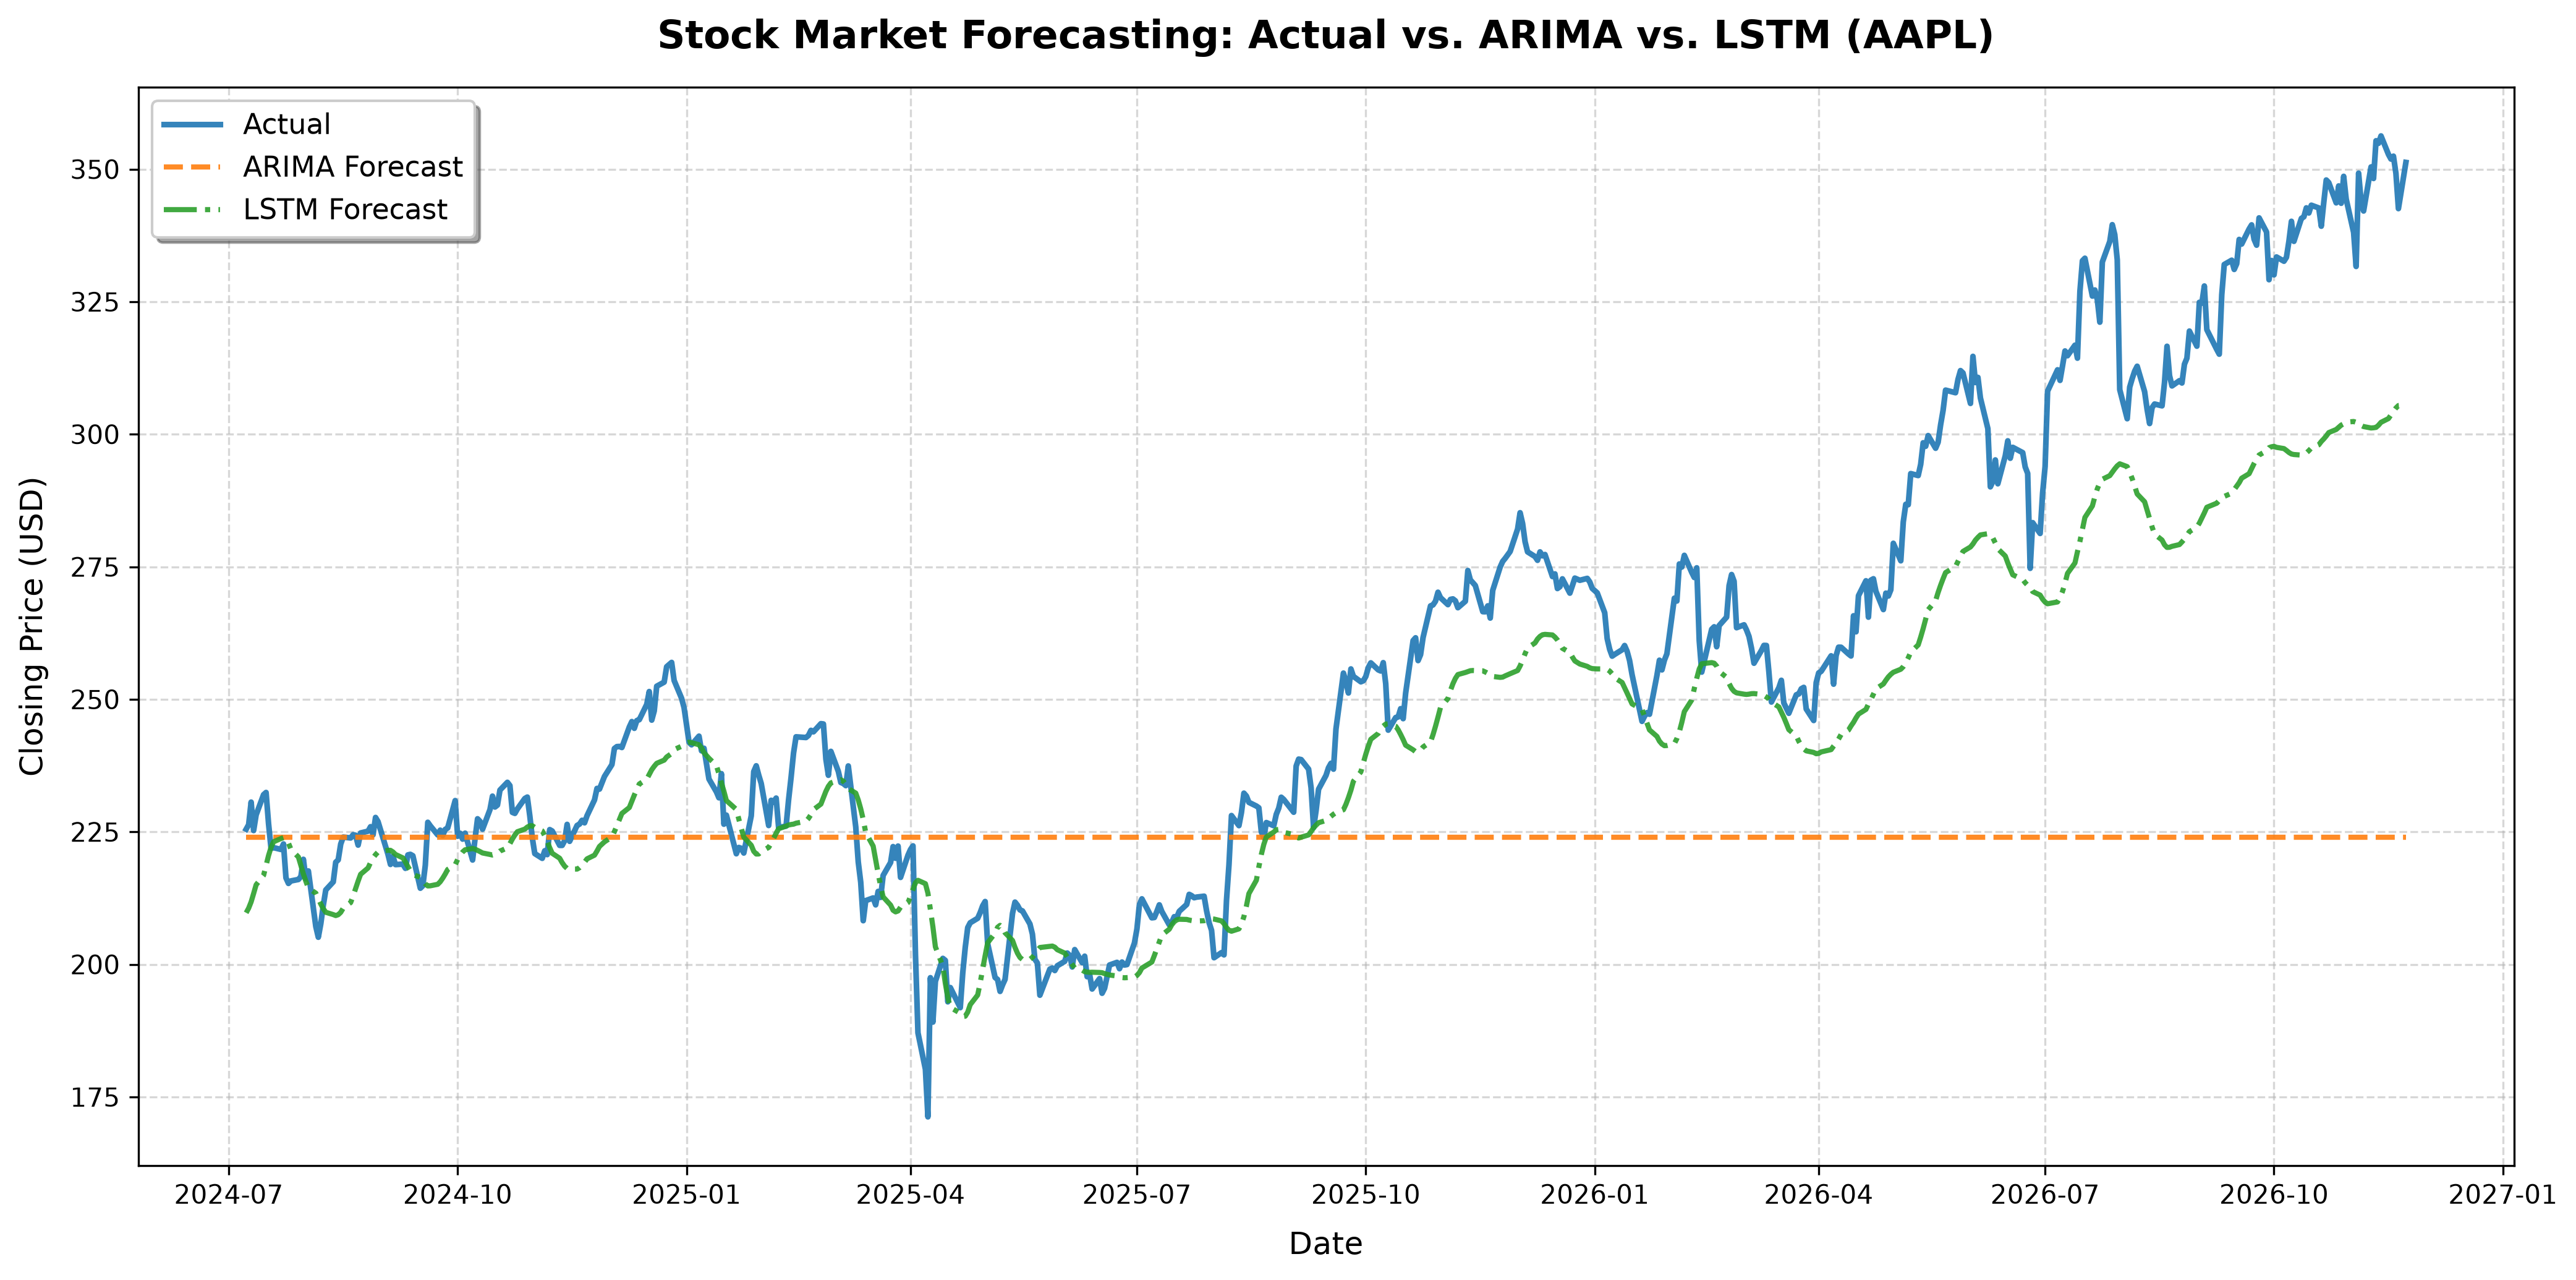

[INFO] Metrics table saved to: ../outputs/metrics.csv

           MODEL PERFORMANCE SUMMARY (TEST SET)          
Model           | MAE (USD)    | RMSE (USD)   | MAPE (%)  
-------------------------------------------------------
ARIMA           | 38.9678      | 53.1896      | 13.67     
LSTM            | 15.7338      | 20.6254      | 5.64      


,Model,MAE,RMSE,MAPE
0,ARIMA,38.9678,53.1896,13.6743
1,LSTM,15.7338,20.6254,5.6425


In [7]:
# Plot final comparison
plot_model_comparison(
    actual_series=test_series,
    arima_forecast=arima_forecast,
    lstm_forecast=lstm_forecast,
    ticker=ticker,
    save_path="../outputs/arima_vs_lstm.png",
    display=True
)

# Save and display comparative metrics table
metrics_records = [
    {"Model": "ARIMA", "MAE": arima_metrics["MAE"], "RMSE": arima_metrics["RMSE"], "MAPE": arima_metrics["MAPE"]},
    {"Model": "LSTM", "MAE": lstm_metrics["MAE"], "RMSE": lstm_metrics["RMSE"], "MAPE": lstm_metrics["MAPE"]},
]

df_metrics = save_and_display_metrics(metrics_records, save_path="../outputs/metrics.csv")
df_metrics